<a href="https://colab.research.google.com/github/MSGamgee85/MSGamgee85/blob/main/ARCH_GARCH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Google Colab](https://img.shields.io/badge/Google%20Colab-%23F9A825.svg?style=for-the-badge&logo=googlecolab&logoColor=black) ![NumPy](https://img.shields.io/badge/numpy-%23013243.svg?style=for-the-badge&logo=numpy&logoColor=white) ![Pandas](https://img.shields.io/badge/pandas-%23150458.svg?style=for-the-badge&logo=pandas&logoColor=white) ![GitHub](https://img.shields.io/badge/github-%23121011.svg?style=for-the-badge&logo=github&logoColor=white)

---

## **Modelos ARCH/GARCH**

---

ARCH é um modelo estatístico utilizado para analisar dados de séries temporais onde a **variância** muda com o **tempo**:

$\sf \sigma^2 = \sigma^2(t)$.

O modelo ARCH é apropriado para séries temporais onde a **variância do erro** segue um <u>modelo autorregressivo (AR)</u>.

Se assumimos que a variância do erro segue um <u>modelo de média móvel autorregressivo (ARMA)</u> então usamos o **Generalized Autoregressive Conditional Heteroskedasticity (GARCH)**.

Os modelos ARCH/GARCH são utilizados principalmente em <u>séries temporais financeiras</u> em que a **volatilidade** apresenta variações com o tempo tornando evidente o fenômeno da **heterocedasticidade**.  

Os **preços** de muitos ativos financeiros tendem a apresentar momento de oscilações brucas de volatilidade intercalados com períodos de relativa calma; a esse fenômeno damos o nome de **agrupamento de volatilidade** (*volatility clustering*).


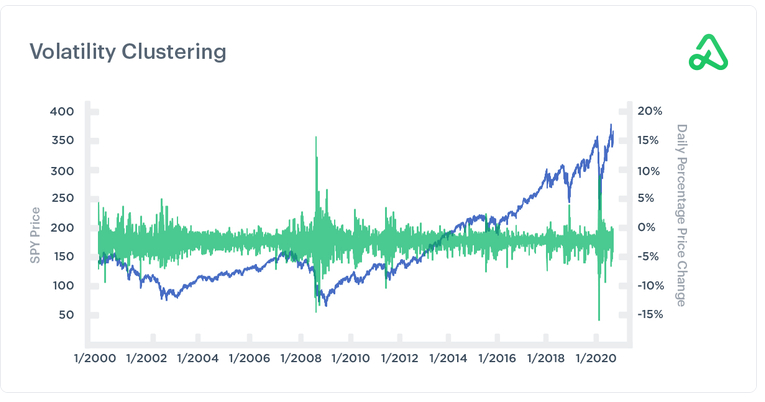

---
**Figura 1.** Agrupamento de volatilidade. Fonte: < https://optionalpha.com/podcast/the-option-alpha-handbook > Acesso em: 09 nov. 2026

## **Conceitos**
---

### **1. Equação da média**

$\boxed{\sf s_t = \mu + \varepsilon_t}$

onde:
* $\sf s_t$ = valor observado no tempo t;
* $\mu$ = média, pode ser constante ou variável no tempo: $\sf \mu = \mu(t)$;
* $\varepsilon_t $ = erro ou resíduo (diferença entre valor real e previsto).


### **2. Erro (Resíduo)**

$\boxed{\sf \varepsilon_t = \sigma_t z_t}$

onde:
* $\sf z_t$ = **ruído branco**: *choques aleatórios* em que geralmente assumimos $\sf z_t \sim N(0,1)$;
* $\sf \sigma_t$ = desvio padrão no instante t: $\sf \sigma  = \sigma(t)$.

### **3. Equação da Variância Condicional**

####**a. ARCH(p)**

$\boxed{\sf \sigma^2_t = \omega + \alpha_1\varepsilon^2_{t-1}+...+\alpha_q\varepsilon^2_{t-p}}$

ou

$\boxed{\sf \sigma^2_t = \omega + \displaystyle \sum_{i=1}^p \alpha_i \varepsilon^2_{t-i}}$

onde:
* $\sf \sigma^2_t$ = **variância esperada** dado valor passado;
* $\sf \omega$ = constante positiva;
* $\sf \alpha_i $ = coeficientes (devem ser $\sf \geq 0$ para todo $\sf i);$
* $\sf \varepsilon^2_{t-p}$ = **resíduos quadráticos** passados capturam *agrupamentos de volatilidade*.

#### **b. GARCH(p,q)**


$\boxed{\sf \sigma^2_t= \omega + \underbrace {\displaystyle \sum_{i=1}^p \alpha_i \varepsilon^2_{t-i}}_{AR(p)}+\underbrace{\displaystyle \sum_{j=1}^q \beta_j\sigma^2_{t-j}}_{MA(q)}}$

onde:
* $\sf \beta_j$ = coeficientes (devem ser $\sf \neq 0$ para todo j);
* $\sf \sigma^2_{t-j}$ = variâncias passadas.

Note que o modelo GARCH assume que a **variância temporal** depende dos valores passados dos erros quadráticos e, também, dos <u>*valores passados da própria variância*</u>.

## **Referências**
---

Geeks For Geeks. **ARCH: Autoregressive Conditional Heteroskedasticity**. Disponível em: < https://www.geeksforgeeks.org/data-science/arch-autoregressive-conditional-heteroskedasticity/ >. Acesso em: 06 nov. 2026

Geeks For Geeks. **GARCH(Generalized Autoregressive Conditional Heteroskedasticity)**. Disponível em: < https://www.geeksforgeeks.org/artificial-intelligence/generalized-autoregressive-conditional-heteroskedasticity/ >. Acesso em: 09 nov. 2026

Wikipedia. **Autoregressive conditional heteroskedasticity**. Disponível em: < https://en.wikipedia.org/wiki/Autoregressive_conditional_heteroskedasticity >. Acesso em: 06 nov. 2026

## **Configuração de ambiente**

---

In [ ]:
# -- Instala pacote ARCH --
!pip install ARCH

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 4.8 MB/s  0:00:00


In [ ]:
# -- Bibliotecas utilizadas --
import numpy as np                # funções matemáticas e operações com arrays [vetores e matrizes]
import pandas as pd               # estruturas tabulares de análise e organização de dados
import yfinance as yf             # base de dados financeiros do YahooFinance
import matplotlib.pyplot as plt   # geração e visualização de gráficos
from arch import arch_model       # modelo ARCH de séries temporais
import warnings                   # gerenciamento de avisos
warnings.filterwarnings('ignore') # ignora avisos

## **1. Modelo ARCH de volatilidade**

---

In [ ]:
# -- Captura dados do ativo --
ativo = "PETR4.SA"
dados = yf.download(ativo, start="2023-01-01", end="2026-01-01")
dados

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA
Date,,,,,
2023-01-02,12.196248,12.669837,12.132393,12.526164,78424700
2023-01-03,11.887619,12.292032,11.775873,12.206893,96750300
2023-01-04,12.265422,12.552768,11.616233,11.685408,129504000
2023-01-05,12.707086,12.792226,12.318636,12.419740,73886000
2023-01-06,12.632588,12.941219,12.531485,12.739013,51851500
...,...,...,...,...,...
2025-12-22,28.346943,28.738878,28.346943,28.483664,35896900
2025-12-23,28.499382,28.743851,28.395954,28.725045,35703900


In [ ]:
# -- Calcula dados de rentabilidade (retorno logarítmico) --
dados['Retornos'] = 100 * np.log(dados['Close']/dados['Close'].shift(1))
dados.dropna(inplace=True)
dados

Price,Close,High,Low,Open,Volume,Retornos
Ticker,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,
Date,,,,,,
2023-01-03,11.887619,12.292032,11.775873,12.206893,96750300,-2.563093
2023-01-04,12.265422,12.552768,11.616233,11.685408,129504000,3.128663
2023-01-05,12.707086,12.792226,12.318636,12.419740,73886000,3.537569
2023-01-06,12.632588,12.941219,12.531485,12.739013,51851500,-0.587990
2023-01-09,12.701766,12.770942,12.371850,12.504880,46385200,0.546119
...,...,...,...,...,...,...
2025-12-22,28.346943,28.738878,28.346943,28.483664,35896900,0.289816
2025-12-23,28.499382,28.743851,28.395954,28.725045,35703900,0.536321


In [ ]:
dados['Vol_Historica'] = dados['Retornos'].std()
dados

Price,Close,High,Low,Open,Volume,Retornos,Vol_Historica
Ticker,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,,
Date,,,,,,,
2023-01-03,11.887619,12.292032,11.775873,12.206893,96750300,-2.563093,1.693078
2023-01-04,12.265422,12.552768,11.616233,11.685408,129504000,3.128663,1.693078
2023-01-05,12.707086,12.792226,12.318636,12.419740,73886000,3.537569,1.693078
2023-01-06,12.632588,12.941219,12.531485,12.739013,51851500,-0.587990,1.693078
2023-01-09,12.701766,12.770942,12.371850,12.504880,46385200,0.546119,1.693078
...,...,...,...,...,...,...,...
2025-12-22,28.346943,28.738878,28.346943,28.483664,35896900,0.289816,1.693078
2025-12-23,28.499382,28.743851,28.395954,28.725045,35703900,0.536321,1.693078


In [ ]:
# -- Modelagem volatilidade usando ARCH(1) --
modelo = arch_model(dados['Retornos'], vol='ARCH', p=1, q=0, dist='normal')
resultado = modelo.fit(disp='off')
print(resultado.summary())

                      Constant Mean - ARCH Model Results                      
Dep. Variable:               Retornos   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:               -1449.68
Distribution:                  Normal   AIC:                           2905.37
Method:            Maximum Likelihood   BIC:                           2919.22
                                        No. Observations:                  748
Date:                Mon, Nov 09 2026   Df Residuals:                      747
Time:                        20:13:29   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1342  6.053e-02      2.217  2.665e-02 [1.554e-0

In [ ]:
dados['Vol_ARCH'] = resultado.conditional_volatility
dados

Price,Close,High,Low,Open,Volume,Retornos,Vol_Historica,Vol_ARCH
Ticker,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,,,
Date,,,,,,,,
2023-01-03,11.887619,12.292032,11.775873,12.206893,96750300,-2.563093,1.693078,1.795929
2023-01-04,12.265422,12.552768,11.616233,11.685408,129504000,3.128663,1.693078,1.869485
2023-01-05,12.707086,12.792226,12.318636,12.419740,73886000,3.537569,1.693078,1.930026
2023-01-06,12.632588,12.941219,12.531485,12.739013,51851500,-0.587990,1.693078,2.020081
2023-01-09,12.701766,12.770942,12.371850,12.504880,46385200,0.546119,1.693078,1.605191
...,...,...,...,...,...,...,...,...
2025-12-22,28.346943,28.738878,28.346943,28.483664,35896900,0.289816,1.693078,1.585047
2025-12-23,28.499382,28.743851,28.395954,28.725045,35703900,0.536321,1.693078,1.583988


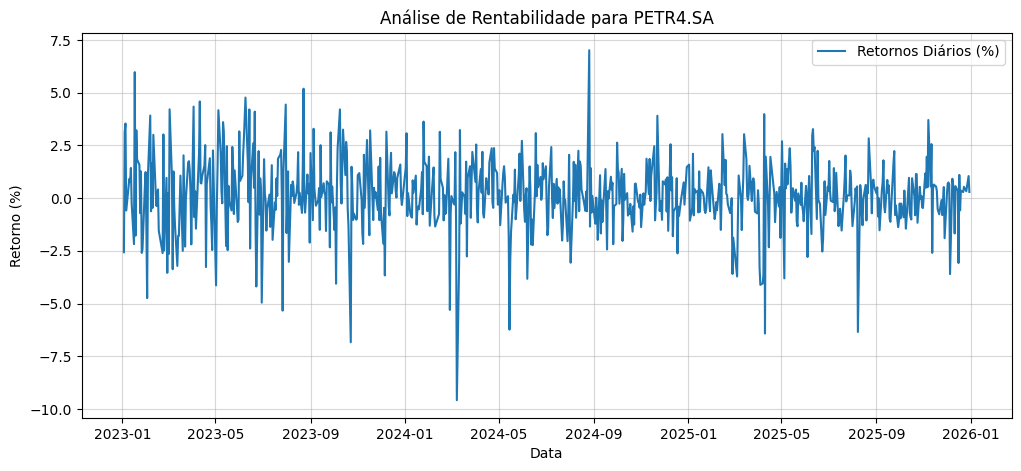

In [ ]:
# Gráfico 1: Rentabilidade Diária
plt.figure(figsize=(12,5))
plt.plot(dados.index, dados['Retornos'], label='Retornos Diários (%)')
plt.title(f"Rentabilidade da {ativo}")
plt.ylabel('Retorno (%)')
plt.xlabel('Data')
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

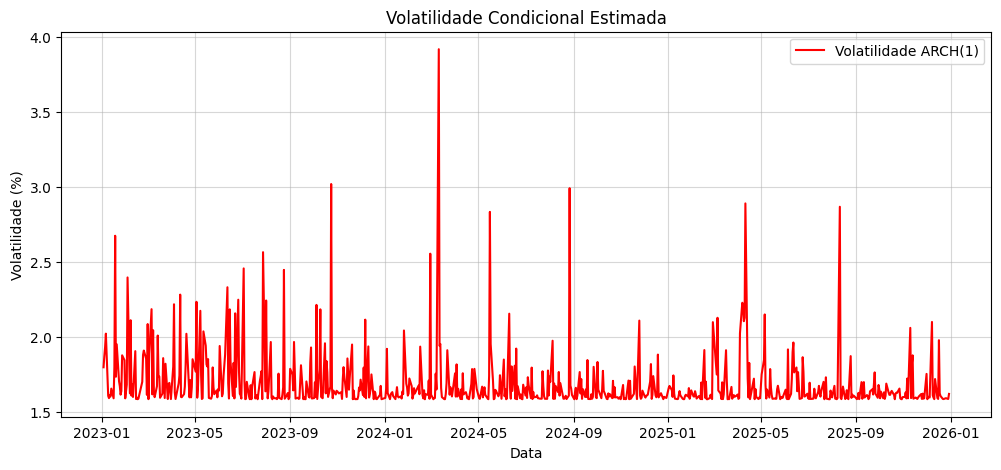

In [ ]:
# Gráfico 2: Volatilidade Condicional Estimada pelo ARCH(1)
plt.figure(figsize=(12,5))
plt.plot(dados.index, dados['Vol_ARCH'], color='red', label='Volatilidade ARCH(1)')
plt.title(f"Volatilidade Condicional Estimada")
plt.xlabel('Data')
plt.ylabel('Volatilidade (%)')
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

## **2. Modelo GARCH de volatilidade**

---